In [1]:
# Project 10: Zomato Restaurant Analysis

# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Load dataset
df = pd.read_csv(
    "../data/raw/Zomato Restaurant Analysis.csv",
    encoding="latin1"
)

# Display first 5 records
df.head()

Matplotlib is building the font cache; this may take a moment.


,Restaurant ID,Restaurant Name,City,Cuisines,Has Online delivery,Aggregate rating,Votes,Average Cost for two
0,6317637,Le Petit Souffle,Makati City,"French, Japanese, Desserts",No,4.8,314,1100
1,6304287,Izakaya Kikufuji,Makati City,Japanese,No,4.5,591,1200
2,6300002,Heat - Edsa Shangri-La,Mandaluyong City,"Seafood, Asian, Filipino, Indian",No,4.4,270,4000
3,6318506,Ooma,Mandaluyong City,"Japanese, Sushi",No,4.9,365,1500
4,6314302,Sambo Kojin,Mandaluyong City,"Japanese, Korean",No,4.8,229,1500


In [ ]:
## Task 2 – Explore the dataset
# A. Check the number of rows and columns
df.shape

(9551, 8)

In [ ]:
# B. Display column names
df.columns

Index(['Restaurant ID', 'Restaurant Name', 'City', 'Cuisines',
       'Has Online delivery', 'Aggregate rating', 'Votes',
       'Average Cost for two'],
      dtype='str')

In [4]:
# C. Check dataset information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   str    
 2   City                  9551 non-null   str    
 3   Cuisines              9542 non-null   str    
 4   Has Online delivery   9551 non-null   str    
 5   Aggregate rating      9551 non-null   float64
 6   Votes                 9551 non-null   int64  
 7   Average Cost for two  9551 non-null   int64  
dtypes: float64(1), int64(3), str(4)
memory usage: 597.1 KB


In [5]:
# D. Generate statistical summary
df.describe()

,Restaurant ID,Aggregate rating,Votes,Average Cost for two
count,9.551000e+03,9551.000000,9551.000000,9551.000000
mean,9.051128e+06,2.666370,156.909748,1199.210763
std,8.791521e+06,1.516378,430.169145,16121.183073
min,5.300000e+01,0.000000,0.000000,0.000000
25%,3.019625e+05,2.500000,5.000000,250.000000
50%,6.004089e+06,3.200000,31.000000,400.000000
75%,1.835229e+07,3.700000,131.000000,700.000000
max,1.850065e+07,4.900000,10934.000000,800000.000000


In [6]:
# E. Check the first and last records
df.head(5)

,Restaurant ID,Restaurant Name,City,Cuisines,Has Online delivery,Aggregate rating,Votes,Average Cost for two
0,6317637,Le Petit Souffle,Makati City,"French, Japanese, Desserts",No,4.8,314,1100
1,6304287,Izakaya Kikufuji,Makati City,Japanese,No,4.5,591,1200
2,6300002,Heat - Edsa Shangri-La,Mandaluyong City,"Seafood, Asian, Filipino, Indian",No,4.4,270,4000
3,6318506,Ooma,Mandaluyong City,"Japanese, Sushi",No,4.9,365,1500
4,6314302,Sambo Kojin,Mandaluyong City,"Japanese, Korean",No,4.8,229,1500


In [7]:
df.tail(5)

,Restaurant ID,Restaurant Name,City,Cuisines,Has Online delivery,Aggregate rating,Votes,Average Cost for two
9546,5915730,NamlÛ± Gurme,ÛÁstanbul,Turkish,No,4.1,788,80
9547,5908749,Ceviz AÛôacÛ±,ÛÁstanbul,"World Cuisine, Patisserie, Cafe",No,4.2,1034,105
9548,5915807,Huqqa,ÛÁstanbul,"Italian, World Cuisine",No,3.7,661,170
9549,5916112,Aôôk Kahve,ÛÁstanbul,Restaurant Cafe,No,4.0,901,120
9550,5927402,Walter's Coffee Roastery,ÛÁstanbul,Cafe,No,4.0,591,55


In [8]:
# F. Check unique values
print("Unique Restaurants:", df["Restaurant ID"].nunique())
print("Unique Cities:", df["City"].nunique())
print("Unique Cuisines:", df["Cuisines"].nunique())
print("Online Delivery Options:", df["Has Online delivery"].unique())

Unique Restaurants: 9551
Unique Cities: 141
Unique Cuisines: 1825
Online Delivery Options: <StringArray>
['No', 'Yes']
Length: 2, dtype: str


In [9]:
## Task 3 – Handle missing values
df.isnull().sum()

Restaurant ID           0
Restaurant Name         0
City                    0
Cuisines                9
Has Online delivery     0
Aggregate rating        0
Votes                   0
Average Cost for two    0
dtype: int64

In [10]:
missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

print(missing_percentage)

Restaurant ID           0.000000
Restaurant Name         0.000000
City                    0.000000
Cuisines                0.094231
Has Online delivery     0.000000
Aggregate rating        0.000000
Votes                   0.000000
Average Cost for two    0.000000
dtype: float64


In [11]:
# Fill missing cuisines with Unknown
df["Cuisines"] = df["Cuisines"].fillna("Unknown")

# Verify missing values
print(df.isnull().sum())

Restaurant ID           0
Restaurant Name         0
City                    0
Cuisines                0
Has Online delivery     0
Aggregate rating        0
Votes                   0
Average Cost for two    0
dtype: int64


In [12]:
## Task 4 – Remove duplicate records
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [13]:
df = df.drop_duplicates()

print("Dataset Shape:", df.shape)

Dataset Shape: (9551, 8)


In [14]:
# Preparring the cleaned dataset
# Rename columns
df.columns = [
    "restaurant_id",
    "restaurant_name",
    "city",
    "cuisines",
    "has_online_delivery",
    "aggregate_rating",
    "votes",
    "average_cost_for_two"
]

# Remove unwanted spaces in text columns
text_columns = [
    "restaurant_name",
    "city",
    "cuisines",
    "has_online_delivery"
]

for column in text_columns:
    df[column] = df[column].astype("string").str.strip()

# Add rating status
df["rating_status"] = np.where(
    df["aggregate_rating"] == 0,
    "Not Rated",
    "Rated"
)

# Save cleaned dataset
os.makedirs("../data/processed", exist_ok=True)

df.to_csv(
    "../data/processed/zomato_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [15]:
## Task 5 – Analyze restaurant ratings
# Rating analysis

rated_df = df[df["aggregate_rating"] > 0]

print("Average Rating:", rated_df["aggregate_rating"].mean())
print("Highest Rating:", rated_df["aggregate_rating"].max())
print("Lowest Rating:", rated_df["aggregate_rating"].min())

print("\nRating Distribution:")
print(df["rating_status"].value_counts())

print("\nTop Rated Restaurants:")
print(
    rated_df.sort_values(
        by="aggregate_rating",
        ascending=False
    )[["restaurant_name", "city", "aggregate_rating"]].head(10)
)

Average Rating: 3.440024314467108
Highest Rating: 4.9
Lowest Rating: 1.8

Rating Distribution:
rating_status
Rated        7403
Not Rated    2148
Name: count, dtype: int64

Top Rated Restaurants:
                restaurant_name            city  aggregate_rating
10             Silantro Fil-Mex      Pasig City               4.9
39                   Coco Bambu       Brasí_lia               4.9
9524               Gaga Manjero          Ankara               4.9
4298             Masala Library       New Delhi               4.9
3601  Indian Accent - The Manor       New Delhi               4.9
1381                Caterspoint         Gurgaon               4.9
2414            Barbeque Nation         Kolkata               4.9
2418  Grandson of Tunday Kababi         Lucknow               4.9
2409            Barbeque Nation         Kolkata               4.9
48           Braseiro da Gíçvea  Rio de Janeiro               4.9


In [16]:
## Task 6 – Analyze cuisine popularity
# Split multiple cuisines into individual records

cuisine_df = df.assign(
    cuisines=df["cuisines"].str.split(",")
).explode("cuisines")

cuisine_df["cuisines"] = cuisine_df["cuisines"].str.strip()

# Count cuisine popularity
cuisine_count = (
    cuisine_df[cuisine_df["cuisines"] != "Unknown"]
    ["cuisines"]
    .value_counts()
)

print("Top 10 Popular Cuisines:")
print(cuisine_count.head(10))

Top 10 Popular Cuisines:
cuisines
North Indian    3960
Chinese         2735
Fast Food       1986
Mughlai          995
Italian          764
Bakery           745
Continental      736
Cafe             703
Desserts         653
South Indian     636
Name: count, dtype: int64


In [17]:
## Task 7 – Analyze city-wise restaurant distribution
city_count = df["city"].value_counts()

print("Top 10 Cities by Restaurant Count:")
print(city_count.head(10))

print("\nLeast 10 Cities by Restaurant Count:")
print(city_count.tail(10))

Top 10 Cities by Restaurant Count:
city
New Delhi       5473
Gurgaon         1118
Noida           1080
Faridabad        251
Ghaziabad         25
Ahmedabad         21
Amritsar          21
Bhubaneshwar      21
Guwahati          21
Lucknow           21
Name: count, dtype: Int64

Least 10 Cities by Restaurant Count:
city
Vernonia            1
Victor Harbor       1
Vineland Station    1
Weirton             1
Winchester Bay      1
Yorkton             1
Mohali              1
Panchkula           1
Bandung             1
Randburg            1
Name: count, dtype: Int64


In [18]:
## Task 8 – Analyze pricing trends
print("Average Cost:", df["average_cost_for_two"].mean())
print("Median Cost:", df["average_cost_for_two"].median())
print("Maximum Cost:", df["average_cost_for_two"].max())
print("Minimum Cost:", df["average_cost_for_two"].min())

# Average cost by city
city_cost = (
    df.groupby("city")["average_cost_for_two"]
    .mean()
    .sort_values(ascending=False)
)

print("\nTop 10 Cities by Average Cost:")
print(city_cost.head(10))

Average Cost: 1199.2107632708617
Median Cost: 400.0
Maximum Cost: 800000
Minimum Cost: 0

Top 10 Cities by Average Cost:
city
Jakarta             308437.500000
Tangerang           250000.000000
Bogor               160000.000000
Bandung             150000.000000
Pasay City            3333.333333
Colombo               2375.000000
Mandaluyong City      2000.000000
Panchkula             2000.000000
Taguig City           1725.000000
Hyderabad             1361.111111
Name: average_cost_for_two, dtype: float64


In [19]:
## Task 9 – Analyze online delivery services
delivery_count = df["has_online_delivery"].value_counts()

print("Online Delivery Analysis:")
print(delivery_count)

delivery_percentage = (
    df["has_online_delivery"].value_counts(normalize=True) * 100
)

print("\nDelivery Percentage:")
print(delivery_percentage.round(2))

Online Delivery Analysis:
has_online_delivery
No     7100
Yes    2451
Name: count, dtype: Int64

Delivery Percentage:
has_online_delivery
No     74.34
Yes    25.66
Name: proportion, dtype: Float64


In [20]:
## Task 10 – Generate business insights
# Generate business insights

total_restaurants = len(df)

average_rating = rated_df["aggregate_rating"].mean()

total_cities = df["city"].nunique()

online_delivery_percentage = (
    (df["has_online_delivery"] == "Yes").mean() * 100
)

most_popular_cuisine = cuisine_count.index[0]

average_cost = df["average_cost_for_two"].mean()

top_city = city_count.index[0]

insights = f"""
ZOMATO RESTAURANT ANALYSIS - BUSINESS INSIGHTS

1. Total Restaurants: {total_restaurants}

2. Average Restaurant Rating: {average_rating:.2f}

3. Total Cities: {total_cities}

4. Online Delivery Percentage:
   {online_delivery_percentage:.2f}%

5. Most Popular Cuisine:
   {most_popular_cuisine}

6. Average Cost for Two:
   {average_cost:.2f} (mixed currency units)

7. City with Highest Restaurant Count:
   {top_city}

"""

print(insights)

# Save business insights
os.makedirs("../outputs/analysis", exist_ok=True)

with open(
    "../outputs/analysis/business_insights.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(insights)

print("Business insights saved successfully!")


ZOMATO RESTAURANT ANALYSIS - BUSINESS INSIGHTS

1. Total Restaurants: 9551

2. Average Restaurant Rating: 3.44

3. Total Cities: 141

4. Online Delivery Percentage:
   25.66%

5. Most Popular Cuisine:
   North Indian

6. Average Cost for Two:
   1199.21 (mixed currency units)

7. City with Highest Restaurant Count:
   New Delhi


Business insights saved successfully!


In [21]:
## Phase 3: Data Visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 100

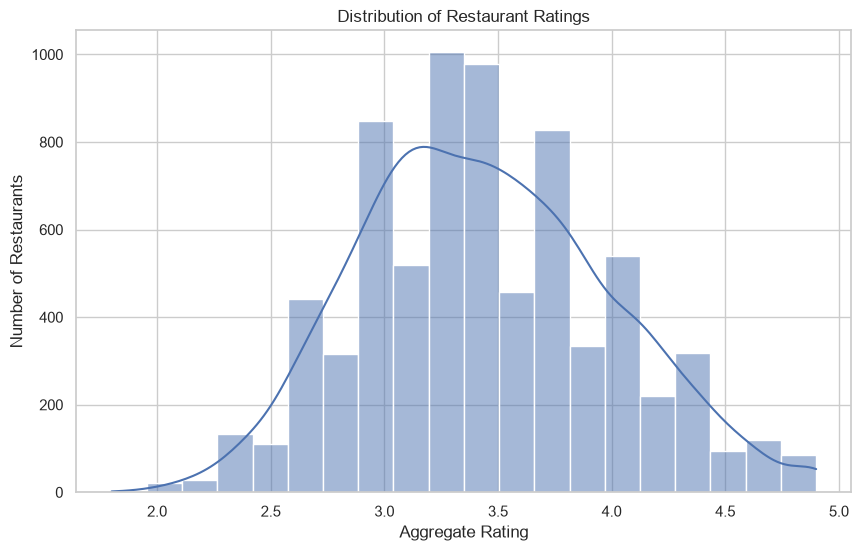

In [22]:
# Visualization 1 – Restaurant Rating Histogram
plt.figure(figsize=(10, 6))

sns.histplot(
    data=rated_df,
    x="aggregate_rating",
    bins=20,
    kde=True
)

plt.title("Distribution of Restaurant Ratings")
plt.xlabel("Aggregate Rating")
plt.ylabel("Number of Restaurants")

plt.savefig("../outputs/graphs/01_rating_histogram.png",
            bbox_inches="tight")

plt.show()

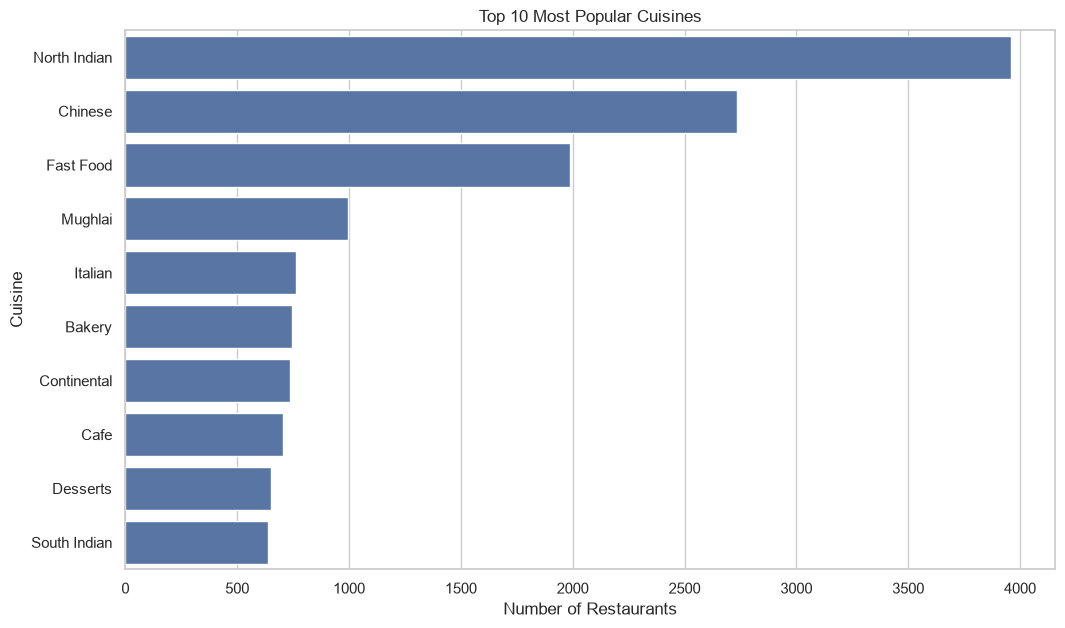

In [23]:
# Visualization 2 – Cuisine Count Plot
plt.figure(figsize=(12, 7))

top_cuisines = cuisine_count.head(10)

sns.barplot(
    x=top_cuisines.values,
    y=top_cuisines.index
)

plt.title("Top 10 Most Popular Cuisines")
plt.xlabel("Number of Restaurants")
plt.ylabel("Cuisine")

plt.savefig("../outputs/graphs/02_cuisine_count.png",
            bbox_inches="tight")

plt.show()

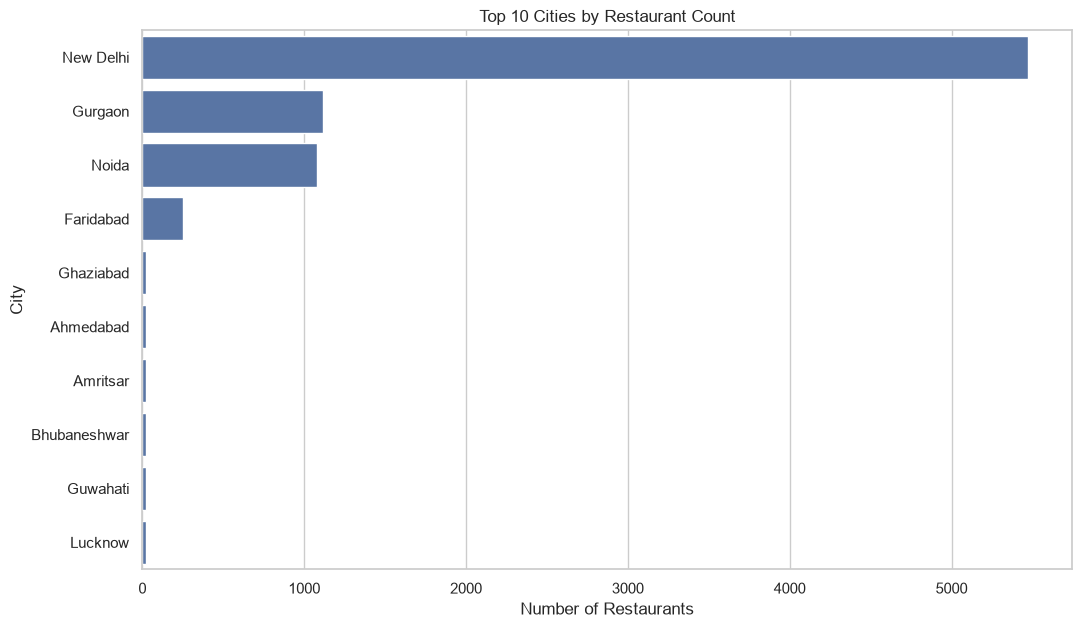

In [25]:
# Visualization 3 – City-wise Restaurant Bar Chart
plt.figure(figsize=(12, 7))

top_cities = city_count.head(10)

sns.barplot(
    x=top_cities.values,
    y=top_cities.index
)

plt.title("Top 10 Cities by Restaurant Count")
plt.xlabel("Number of Restaurants")
plt.ylabel("City")

plt.savefig("../outputs/graphs/03_city_restaurant_count.png",
            bbox_inches="tight")

plt.show()

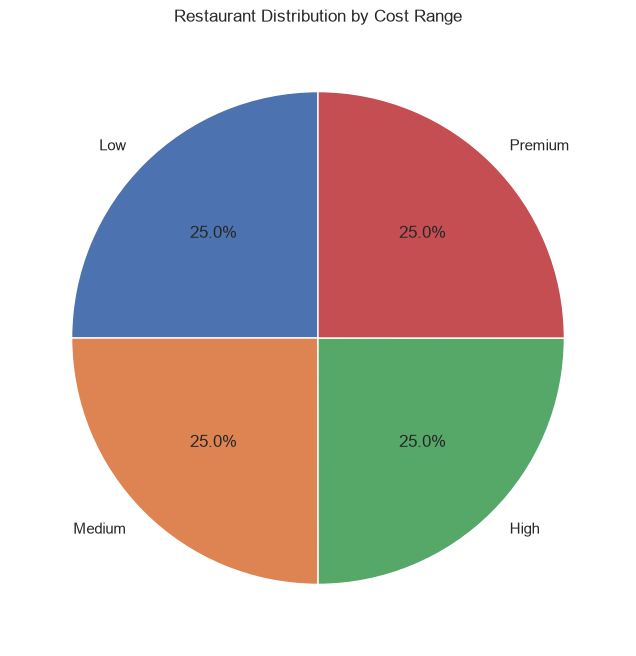

In [26]:
# Visualization 4 – Price Range Pie Chart
df["price_range"] = pd.qcut(
    df["average_cost_for_two"].rank(method="first"),
    q=4,
    labels=["Low", "Medium", "High", "Premium"]
)

price_counts = df["price_range"].value_counts().reindex(
    ["Low", "Medium", "High", "Premium"]
)

plt.figure(figsize=(8, 8))

plt.pie(
    price_counts,
    labels=price_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Restaurant Distribution by Cost Range")

plt.savefig("../outputs/graphs/04_price_range_pie.png",
            bbox_inches="tight")

plt.show()

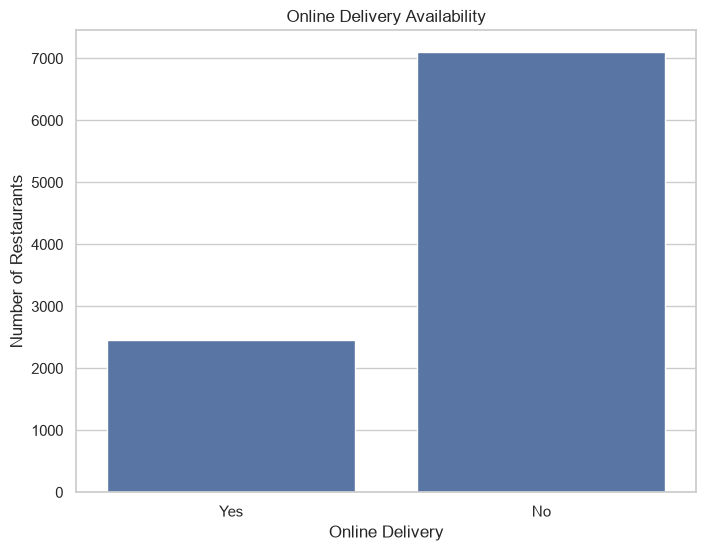

In [27]:
# Visualization 5 – Online Delivery Count Plot
plt.figure(figsize=(8, 6))

sns.countplot(
    data=df,
    x="has_online_delivery",
    order=["Yes", "No"]
)

plt.title("Online Delivery Availability")
plt.xlabel("Online Delivery")
plt.ylabel("Number of Restaurants")

plt.savefig("../outputs/graphs/05_online_delivery_count.png",
            bbox_inches="tight")

plt.show()

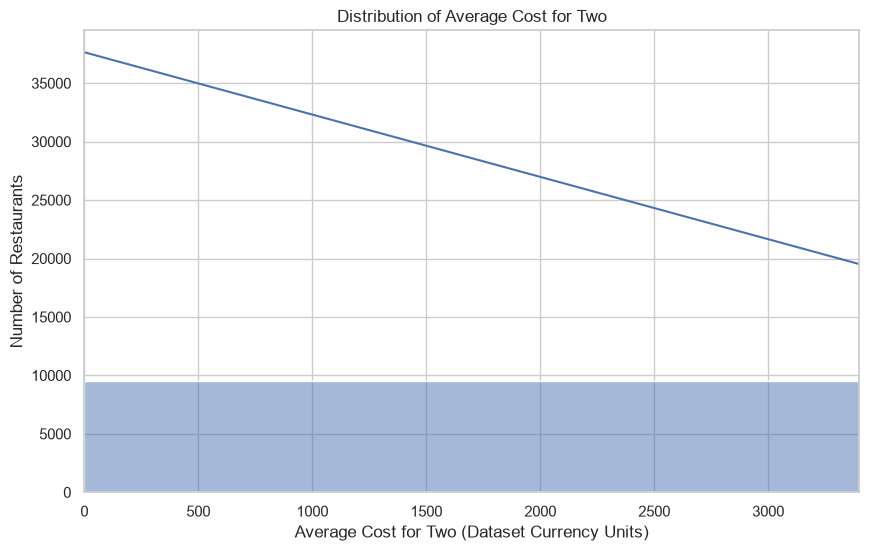

In [28]:
# Visualization 6 – Cost Distribution Histogram
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="average_cost_for_two",
    bins=30,
    kde=True
)

# Limit displayed range to reduce the impact of extreme outliers
plt.xlim(0, df["average_cost_for_two"].quantile(0.99))

plt.title("Distribution of Average Cost for Two")
plt.xlabel("Average Cost for Two (Dataset Currency Units)")
plt.ylabel("Number of Restaurants")

plt.savefig("../outputs/graphs/06_cost_distribution.png",
            bbox_inches="tight")

plt.show()

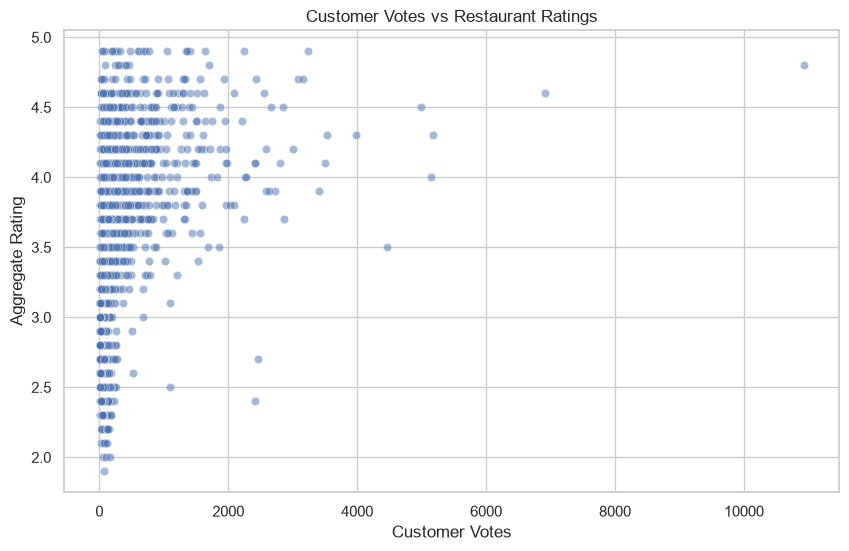

In [29]:
# Visualization 7 – Customer Votes Scatter Plot
votes_sample = rated_df.sample(
    n=min(3000, len(rated_df)),
    random_state=42
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=votes_sample,
    x="votes",
    y="aggregate_rating",
    alpha=0.5
)

plt.title("Customer Votes vs Restaurant Ratings")
plt.xlabel("Customer Votes")
plt.ylabel("Aggregate Rating")

plt.savefig("../outputs/graphs/07_votes_scatter.png",
            bbox_inches="tight")

plt.show()

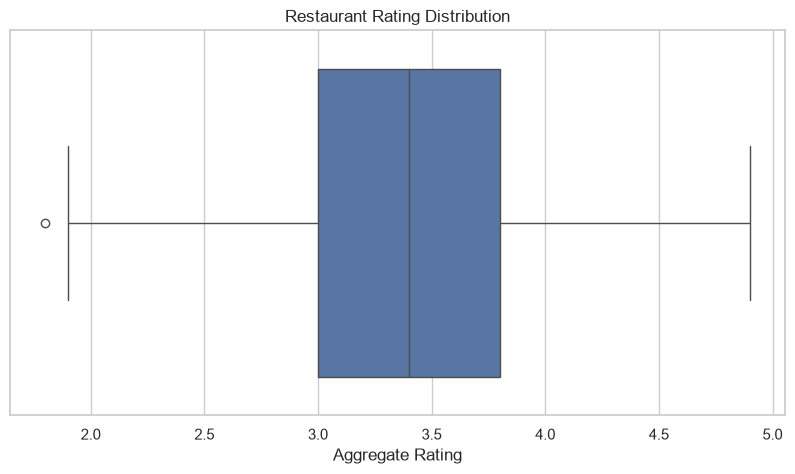

In [30]:
# Visualization 8 – Rating Box Plot
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=rated_df,
    x="aggregate_rating"
)

plt.title("Restaurant Rating Distribution")
plt.xlabel("Aggregate Rating")

plt.savefig("../outputs/graphs/08_rating_boxplot.png",
            bbox_inches="tight")

plt.show()

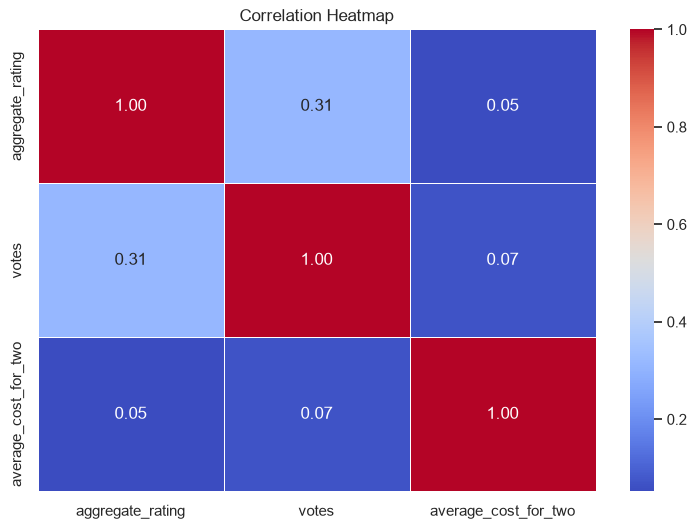

In [31]:
# Visualization 9 – Correlation Heatmap
numeric_columns = [
    "aggregate_rating",
    "votes",
    "average_cost_for_two"
]

correlation = df[numeric_columns].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")

plt.savefig("../outputs/graphs/09_correlation_heatmap.png",
            bbox_inches="tight")

plt.show()

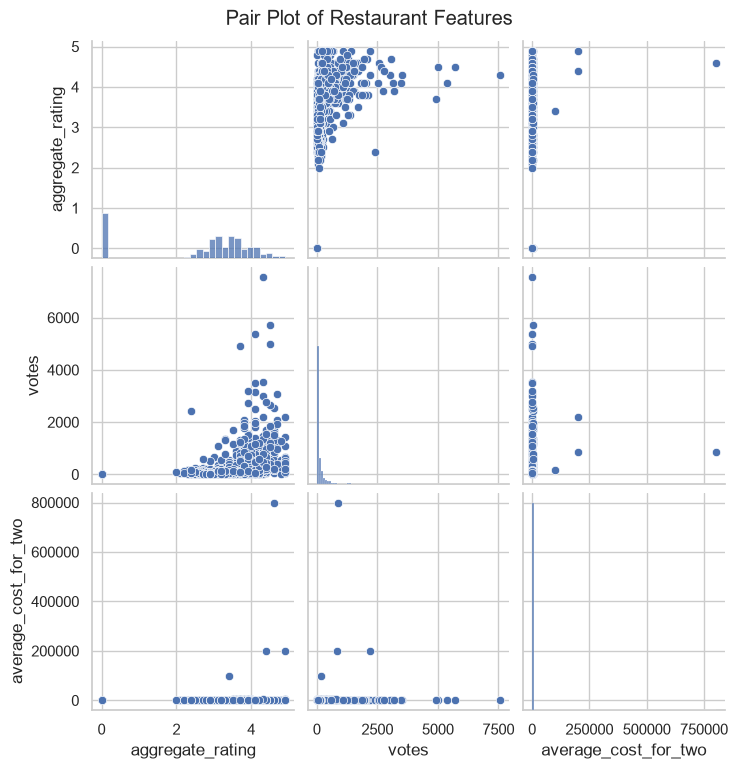

In [32]:
# Visualization 10 – Pair Plot
pairplot_data = df[
    [
        "aggregate_rating",
        "votes",
        "average_cost_for_two"
    ]
].sample(
    n=min(2000, len(df)),
    random_state=42
)

pairplot = sns.pairplot(
    pairplot_data,
    diag_kind="hist"
)

pairplot.fig.suptitle(
    "Pair Plot of Restaurant Features",
    y=1.02
)

pairplot.fig.savefig(
    "../outputs/graphs/10_pairplot.png",
    bbox_inches="tight"
)

plt.show()